(what-batting-average-to-publish)=
# Player-season batting averages

A season average is a proportion of hits to at-bats. For a player-season with at least 100 at-bats (plate appearances that count toward the average) it sits strictly inside (0, 1): in this file the lowest is just under 0.12 and the highest is just under 0.38. The desk is not deciding a binary "did he play" and not reserving a bill that can be zero. It is deciding which expected average to write down, and how sure to be, once the role is known.

The file is the Baseball Databank. Batting lines are `core/Batting.csv` and birth year and batting hand are `core/People.csv`, from `https://raw.githubusercontent.com/cbwinslow/baseballdatabank/master/core/`. The databank's last season in this file is 2021. Stints (one team's run within a season) in the same year are summed. Rows are the 2000-2021 player-seasons with at least 100 at-bats. Most of the databank comes from the Chadwick Baseball Bureau and is distributed as open data.

The candidates are a constant beta (a distribution on the interval (0, 1)) and a constant Gaussian, a linear regression, a logit-normal, a binomial model for the hits themselves, a beta regression whose precision (phi, the inverse of the dispersion) depends on at-bats, and the same linear mean and beta boosted. Players, not seasons, are held out, so one player's years do not train the model that scores him.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the expected batting average of a player-season |
| **Observed response** | hits divided by at-bats, strictly inside (0, 1) |
| **Estimand** | held-out negative log density of that average, and mean absolute error |
| **Units** | nats per player-season, lower is better; batting-average points |
| **Sampling unit** | one row is one player-season with hits and at-bats |
| **Dependence** | Repeated seasons from a player are related; every season of that player stays in the same partition. |
| **Split and tuning** | players, 20% choose steps, 20% held out; every season of a player stays together |
| **Information** | age, at-bats, league, and batting hand |
| **Uncertainty** | fitted predictive distributions are scored; no resampling confidence intervals for score differences are reported |
| **Claim type** | predictive comparisons conditional on the recorded covariates; no causal effects are estimated |
| **What this does not estimate** | a causal effect of playing time, a rate for a pitcher, or a projection before any at-bats |

:::


In [1]:
import warnings
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from sklearn.linear_model import LinearRegression
from statsmodels.othermod.betareg import BetaModel
from statsmodels.tools import add_constant

import mboostrs as mb

path = Path("batting_average.csv")
if not path.exists():
    path = Path("docs/book/case_studies/batting_average.csv")
raw = pl.read_csv(path, comment_prefix="#")
frame = raw.with_columns(
    (pl.col("h") / pl.col("ab")).alias("avg"),
    (pl.col("age") - 28.0).alias("age_28"),
    ((pl.col("age") - 28.0) ** 2).alias("age_28_sq"),
    pl.col("ab").log().alias("log_ab"),
    (pl.col("lg") == "AL").cast(pl.Float64).alias("lg_al"),
    (pl.col("bats") == "L").cast(pl.Float64).alias("bats_l"),
    (pl.col("bats") == "B").cast(pl.Float64).alias("bats_b"),
)
identity_gap = float((frame["h"] / frame["ab"] - frame["avg"]).abs().max())
mean_cols = ["age_28", "age_28_sq", "log_ab", "lg_al", "bats_l", "bats_b"]
mean_formula = "avg ~ " + " + ".join(mean_cols)

players = frame["player_id"].unique().sort().to_numpy().copy()
rng = np.random.default_rng(20261004)
rng.shuffle(players)
n_players = len(players)
n_test = int(round(0.20 * n_players))
n_valid = int(round(0.20 * n_players))
test_players = set(players[:n_test])
valid_players = set(players[n_test : n_test + n_valid])
train_players = set(players[n_test + n_valid :])


def seasons_of(ids):
    return frame.filter(pl.col("player_id").is_in(list(ids)))


train = seasons_of(train_players)
valid = seasons_of(valid_players)
fit_rows = pl.concat([train, valid])
test = seasons_of(test_players)
print(
    f"{frame.height} seasons, {n_players} players, average from {float(frame['avg'].min()):.3f} to {float(frame['avg'].max()):.3f}; "
    f"{len(train_players)} players to fit the path, {len(valid_players)} to choose steps, "
    f"{fit_rows.height} seasons refit, {test.height} held out; hits/at-bats gap {identity_gap:.1e}"
)


9332 seasons, 1901 players, average from 0.117 to 0.373; 1141 players to fit the path, 380 to choose steps, 7370 seasons refit, 1962 held out; hits/at-bats gap 0.0e+00


In [2]:
def columns_of(data):
    return {name: data[name].to_numpy() for name in data.columns}


def mean_exog(data):
    return add_constant(np.column_stack([data[name].to_numpy() for name in mean_cols]), has_constant="add")


def precision_exog(data):
    return add_constant(data["log_ab"].to_numpy(), has_constant="add")


def mae(y, mu):
    return float(np.mean(np.abs(np.asarray(y, dtype=float) - np.asarray(mu, dtype=float))))


def beta_neglog(y, mu, phi):
    return float(-np.mean(stats.beta.logpdf(y, a=mu * phi, b=(1.0 - mu) * phi)))


def gaussian_neglog(y, mu, sigma):
    return float(-np.mean(stats.norm.logpdf(y, loc=mu, scale=sigma)))


def logit_normal_neglog(y, loc, sigma):
    z = np.log(y / (1.0 - y))
    return float(-np.mean(stats.norm.logpdf(z, loc=loc, scale=sigma) - np.log(y) - np.log(1.0 - y)))


def logit_normal_mean(loc, sigma, n_nodes=41):
    nodes = stats.norm.ppf((np.arange(n_nodes) + 0.5) / n_nodes)
    return np.mean(1.0 / (1.0 + np.exp(-(loc[:, None] + sigma * nodes[None, :]))), axis=1)


y_test = test["avg"].to_numpy()
y_fit = fit_rows["avg"].to_numpy()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ols = smf.ols(mean_formula, columns_of(fit_rows)).fit()
    logged = {**columns_of(fit_rows), "z": np.log(y_fit / (1.0 - y_fit))}
    logit_normal = smf.ols("z ~ " + " + ".join(mean_cols), logged).fit()
    hits = np.column_stack([fit_rows["h"].to_numpy(), fit_rows["ab"].to_numpy() - fit_rows["h"].to_numpy()])
    binomial = sm.GLM(hits, mean_exog(fit_rows), family=sm.families.Binomial()).fit()
    beta = BetaModel(y_fit, mean_exog(fit_rows), exog_precision=precision_exog(fit_rows)).fit(disp=0)
    linear = LinearRegression().fit(mean_exog(fit_rows)[:, 1:], y_fit)

ols_mu = np.asarray(ols.predict(columns_of(test)), dtype=float)
ols_sigma = float(np.sqrt(ols.scale))
sklearn_mu = np.asarray(linear.predict(mean_exog(test)[:, 1:]), dtype=float)
sklearn_sigma = float(np.sqrt(np.mean((y_fit - linear.predict(mean_exog(fit_rows)[:, 1:])) ** 2)))
sklearn_gap = float(np.max(np.abs(sklearn_mu - ols_mu)))
binomial_mu = np.asarray(binomial.predict(mean_exog(test)), dtype=float)
beta_mu = np.asarray(beta.predict(exog=mean_exog(test), exog_precision=precision_exog(test), which="mean"))
beta_phi = np.asarray(beta.predict(exog=mean_exog(test), exog_precision=precision_exog(test), which="precision"))
logit_loc = np.asarray(logit_normal.predict(columns_of(test)), dtype=float)
logit_sigma = float(np.sqrt(logit_normal.scale))
logit_mu = logit_normal_mean(logit_loc, logit_sigma)
a_bar, b_bar, _loc, _scale = stats.beta.fit(y_fit, floc=0, fscale=1)
const_mu = float(a_bar / (a_bar + b_bar))
const_gauss = float(np.mean(y_fit))
const_gauss_sigma = float(np.std(y_fit, ddof=0))
binomial_converged = bool(binomial.converged)


In [3]:
def operating_step(curve, tolerance):
    best = min(score for _, score in curve)
    step = min(k for k, score in curve if score <= best + tolerance)
    last_step, last_score = curve[-1]
    earlier = [score for k, score in curve if k <= last_step - 80]
    still_falling = bool(earlier) and earlier[-1] - last_score > 0.005 and last_score <= best + 1e-12
    return step, still_falling


y_valid = valid["avg"].to_numpy()
gauss_path = mb.glmboost(mean_formula, train, family=mb.Gaussian(), control=mb.boost_control(200, 0.1))
gauss_curve = []
for step in range(10, 201, 10):
    model = gauss_path.with_mstop(step)
    pred = np.asarray(model.predict(valid, type="response"), dtype=float).ravel()
    fitted = np.asarray(model.predict(type="response"), dtype=float).ravel()
    sigma = float(np.sqrt(np.mean((train["avg"].to_numpy() - fitted) ** 2)))
    gauss_curve.append((step, gaussian_neglog(y_valid, pred, sigma)))
step_gauss, gauss_at_cap = operating_step(gauss_curve, 0.002)

beta_family = mb.BetaLSS()
beta_formulas = {"mu": mean_formula, "phi": "avg ~ log_ab"}
beta_curve = []
for step in (20, 40, 80, 120, 160, 200):
    cold = mb.glmboostLSS(beta_formulas, train, families=beta_family, control=mb.boost_control(step, 0.1))
    params = cold.predict(valid, type="response")
    beta_curve.append((step, beta_neglog(y_valid, params["mu"], params["phi"])))
step_beta, beta_at_cap = operating_step(beta_curve, 0.002)
print("steps", {"gaussian": step_gauss, "beta": step_beta}, "still at cap", {"gaussian": gauss_at_cap, "beta": beta_at_cap})


steps {'gaussian': 20, 'beta': 20} still at cap {'gaussian': False, 'beta': False}


In [4]:
gauss_fit = mb.glmboost(mean_formula, fit_rows, family=mb.Gaussian(), control=mb.boost_control(step_gauss, 0.1))
gauss_mu = np.asarray(gauss_fit.predict(test, type="response"), dtype=float).ravel()
gauss_sigma = float(np.sqrt(np.mean((y_fit - np.asarray(gauss_fit.predict(type="response"), dtype=float).ravel()) ** 2)))
beta_fit = mb.glmboostLSS(beta_formulas, fit_rows, families=beta_family, control=mb.boost_control(step_beta, 0.1))
beta_boost = beta_fit.predict(test, type="response")
rows = []


def add(method, log_score, error, mstop=None, at_cap=None, note=""):
    rows.append({
        "method": method,
        "log_score": log_score,
        "mae": error,
        "mstop": mstop,
        "at_cap": at_cap,
        "note": note,
    })


add("beta regression", beta_neglog(y_test, beta_mu, beta_phi), mae(y_test, beta_mu), note="precision on log at-bats")
add(
    "logit-normal",
    logit_normal_neglog(y_test, logit_loc, logit_sigma),
    mae(y_test, logit_mu),
    note=f"sigma {logit_sigma:.3f}; mean by quadrature",
)
add("statsmodels OLS", gaussian_neglog(y_test, ols_mu, ols_sigma), mae(y_test, ols_mu), note=f"sigma {ols_sigma:.4f}")
add(
    "sklearn LinearRegression",
    gaussian_neglog(y_test, sklearn_mu, sklearn_sigma),
    mae(y_test, sklearn_mu),
    note=f"max gap vs OLS {sklearn_gap:.1e}",
)
add(
    "glmboost Gaussian",
    gaussian_neglog(y_test, gauss_mu, gauss_sigma),
    mae(y_test, gauss_mu),
    mstop=step_gauss,
    at_cap=gauss_at_cap,
    note=f"outside (0, 1): {float(((gauss_mu <= 0) | (gauss_mu >= 1)).mean()):.3f}",
)
add(
    "glmboostLSS beta",
    beta_neglog(y_test, beta_boost["mu"], beta_boost["phi"]),
    mae(y_test, beta_boost["mu"]),
    mstop=step_beta,
    at_cap=beta_at_cap,
    note="phi on log at-bats",
)
add(
    "constant beta",
    float(-np.mean(stats.beta.logpdf(y_test, a_bar, b_bar))),
    mae(y_test, np.full(len(y_test), const_mu)),
    note=f"mean {const_mu:.3f}",
)
add(
    "constant Gaussian",
    gaussian_neglog(y_test, np.full(len(y_test), const_gauss), const_gauss_sigma),
    mae(y_test, np.full(len(y_test), const_gauss)),
    note=f"sigma {const_gauss_sigma:.4f}",
)
add(
    "binomial GLM",
    None,
    mae(y_test, binomial_mu),
    note=f"converged {binomial_converged}; expected hits per at-bat",
)
summary = pl.DataFrame(rows).sort("log_score", nulls_last=True)
display(summary)
short = (test["ab"].to_numpy() < 200)
long = (test["ab"].to_numpy() >= 400)
short_beta = beta_neglog(y_test[short], beta_mu[short], beta_phi[short])
short_gauss = gaussian_neglog(y_test[short], ols_mu[short], ols_sigma)
long_beta = beta_neglog(y_test[long], beta_mu[long], beta_phi[long])
long_gauss = gaussian_neglog(y_test[long], ols_mu[long], ols_sigma)


method,log_score,mae,mstop,at_cap,note
str,f64,f64,i64,bool,str
"""beta regression""",-2.043001,0.025378,null,null,"""precision on log at-bats"""
"""statsmodels OLS""",-2.022583,0.02537,null,null,"""sigma 0.0314"""
"""sklearn LinearRegression""",-2.022564,0.02537,null,null,"""max gap vs OLS 8.9e-14"""
"""glmboost Gaussian""",-2.019908,0.025461,20,false,"""outside (0, 1): 0.000"""
"""logit-normal""",-2.005897,0.025348,null,null,"""sigma 0.169; mean by quadratur…"
"""glmboostLSS beta""",-1.97032,0.025822,20,false,"""phi on log at-bats"""
"""constant Gaussian""",-1.915707,0.028105,null,null,"""sigma 0.0354"""
"""constant beta""",-1.90356,0.028105,null,null,"""mean 0.257"""
"""binomial GLM""",null,0.025401,null,null,"""converged True; expected hits …"


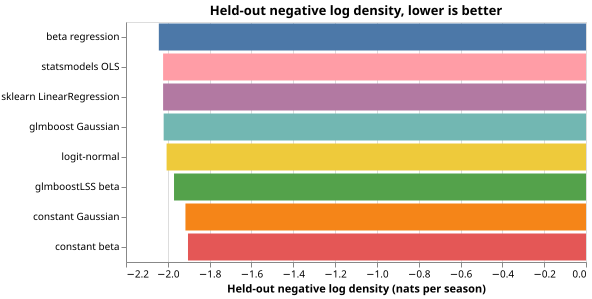

In [5]:
scored = summary.filter(pl.col("log_score").is_not_null())
alt.Chart(scored).mark_bar().encode(
    x=alt.X("log_score:Q", title="Held-out negative log density (nats per season)", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(width=460, height=240, title="Held-out negative log density, lower is better")


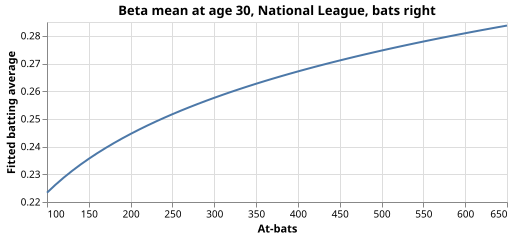

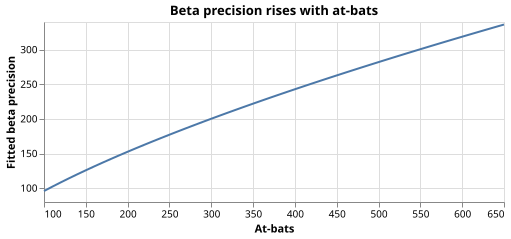

In [6]:
ab_grid = np.arange(100, 651, 10)
age_28 = 2.0
design = np.column_stack([
    np.ones(len(ab_grid)),
    np.full(len(ab_grid), age_28),
    np.full(len(ab_grid), age_28 ** 2),
    np.log(ab_grid),
    np.zeros(len(ab_grid)),
    np.zeros(len(ab_grid)),
    np.zeros(len(ab_grid)),
])
curve = pl.DataFrame({
    "at_bats": ab_grid,
    "mean": 1.0 / (1.0 + np.exp(-design @ np.asarray(beta.params[:7], dtype=float))),
    "precision": np.exp(np.column_stack([np.ones(len(ab_grid)), np.log(ab_grid)]) @ np.asarray(beta.params[7:], dtype=float)),
})
mean_chart = alt.Chart(curve).mark_line().encode(
    x=alt.X("at_bats:Q", title="At-bats"),
    y=alt.Y("mean:Q", title="Fitted batting average", scale=alt.Scale(zero=False)),
).properties(width=460, height=180, title="Beta mean at age 30, National League, bats right")
precision_chart = alt.Chart(curve).mark_line().encode(
    x=alt.X("at_bats:Q", title="At-bats"),
    y=alt.Y("precision:Q", title="Fitted beta precision", scale=alt.Scale(zero=False)),
).properties(width=460, height=180, title="Beta precision rises with at-bats")
display(mean_chart)
display(precision_chart)


def beta_mean_at(age, at_bats, lg_al=0.0):
    row = np.array([1.0, age - 28.0, (age - 28.0) ** 2, np.log(at_bats), lg_al, 0.0, 0.0])
    eta = float(np.dot(np.asarray(beta.params[:7], dtype=float), row))
    return float(1.0 / (1.0 + np.exp(-eta)))


## Results and interpretation

Publish the beta regression. On the held-out seasons its negative log density is {eval}`f"{float(summary.filter(pl.col('method')=='beta regression')['log_score'][0]):.3f}"` nats and its mean absolute error is {eval}`f"{float(summary.filter(pl.col('method')=='beta regression')['mae'][0]):.3f}"`. The constant beta scores {eval}`f"{float(summary.filter(pl.col('method')=='constant beta')['log_score'][0]):.3f}"`. The covariates are worth that gap. The linear regression scores {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels OLS')['log_score'][0]):.3f}"` and the logit-normal {eval}`f"{float(summary.filter(pl.col('method')=='logit-normal')['log_score'][0]):.3f}"`. Sklearn's unpenalized linear fit matches the OLS mean to {eval}`f"{sklearn_gap:.1e}"`. The Gaussian boost, {eval}`str(int(summary.filter(pl.col('method')=='glmboost Gaussian')['mstop'][0]))` steps, scores {eval}`f"{float(summary.filter(pl.col('method')=='glmboost Gaussian')['log_score'][0]):.3f}"`. None of these is a better distribution than the closed-form beta.

The printed average is not where they differ. The largest gap between the beta mean and the OLS mean on the held-out seasons is {eval}`f"{float(np.max(np.abs(beta_mu - ols_mu))):.4f}"`. Absolute error for every covariate model is about {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels OLS')['mae'][0]):.3f}"`, against {eval}`f"{float(summary.filter(pl.col('method')=='constant beta')['mae'][0]):.3f}"` for the constant. The binomial GLM, which is the sampling model for hits in a fixed number of at-bats, has absolute error {eval}`f"{float(summary.filter(pl.col('method')=='binomial GLM')['mae'][0]):.3f}"` and converged. Use it if the question is the expected hit count. It does not score the average as a density. The beta does.

At-bats, not age, move the mean. A National League right-handed season at age 30 is fit at {eval}`f"{beta_mean_at(30, 500):.3f}"` with 500 at-bats and {eval}`f"{beta_mean_at(30, 150):.3f}"` with 150. That is who plays a full season in this file, not a reason to give someone more at-bats. The same comparison at age 23 and age 36, both with 500 at-bats, is {eval}`f"{beta_mean_at(23, 500):.3f}"` and {eval}`f"{beta_mean_at(36, 500):.3f}"`. Do not publish an aging peak from qualified seasons (at least 100 at-bats in the season). The players who still have 100 at-bats at either end of this age range are a selected group, and the fitted curve is nearly flat. The American League coefficient on the logit is {eval}`f"{float(beta.params[4]):.3f}"` (standard error {eval}`f"{float(beta.bse[4]):.3f}"`). At age 30 and 500 at-bats that is {eval}`f"{beta_mean_at(30, 500, 1) - beta_mean_at(30, 500):.3f}"` on the average.

The beta model allows residual variance to change with at-bats. Precision rises with log at-bats, coefficient {eval}`f"{float(beta.params[8]):.3f}"` (standard error {eval}`f"{float(beta.bse[8]):.3f}"`). On held-out seasons under 200 at-bats the beta scores {eval}`f"{short_beta:.3f}"` and the Gaussian {eval}`f"{short_gauss:.3f}"`. On seasons of at least 400 at-bats the two are {eval}`f"{long_beta:.3f}"` and {eval}`f"{long_gauss:.3f}"`. A constant residual variance understates variation for short seasons and
overstates it for long seasons in this comparison. The OLS mean is outside (0, 1) for {eval}`f"{float(((ols_mu <= 0) | (ols_mu >= 1)).mean()):.1%}"` of the held-out seasons, so the boundary is not the objection. The limitation here is its constant residual variance.

Do not publish the boosted beta. At {eval}`str(int(summary.filter(pl.col('method')=='glmboostLSS beta')['mstop'][0]))` steps it scores {eval}`f"{float(summary.filter(pl.col('method')=='glmboostLSS beta')['log_score'][0]):.3f}"`, better than the constant and short of the closed form. Steps past that did not improve the tuning score enough to take them. The likelihood of that fit matches the beta density, so the path really is that far from the maximum likelihood estimate.

This is the average to attach to a 2000-2021 player-season that already has at least 100 at-bats. It is not a projection for someone who has not played, and not a pitcher's line.


In [7]:
train_params = beta_fit.predict(type="response")
hand = float(np.sum(stats.beta.logpdf(
    y_fit, a=train_params["mu"] * train_params["phi"], b=(1.0 - train_params["mu"]) * train_params["phi"]
)))
pdf = beta_family.pdf(y_fit, train_params)
beta_ll_gap = abs(float(beta_fit.logLik()) - hand)
pdf_gap = abs(hand - float(np.sum(np.log(pdf))))
link = np.asarray(gauss_fit.predict(type="link"), dtype=float).ravel()
response = np.asarray(gauss_fit.predict(type="response"), dtype=float).ravel()
gauss_link_gap = float(np.max(np.abs(link - response)))
print("beta logLik", beta_ll_gap)
print("pdf", pdf_gap)
print("gaussian link", gauss_link_gap)
print("caps", gauss_at_cap, beta_at_cap)


beta logLik 1.2732925824820995e-11
pdf 1.8189894035458565e-12
gaussian link 0.0
caps False False


## API behavior and limitations

`BetaLSS` `type="response"` returns `mu`, the mean on (0, 1), and `phi`, the precision. The density is the beta with shapes `mu * phi` and `(1 - mu) * phi`. `logLik()` matches that log density to {eval}`f"{beta_ll_gap:.1e}"`, and `pdf` matches the same number to {eval}`f"{pdf_gap:.1e}"`. A caller who treats `phi` as a variance has it backwards: a larger `phi` is a tighter average.

`Gaussian` `type="link"` and `type="response"` are the same mean on this fit, to {eval}`f"{gauss_link_gap:.1e}"`. The log score then needs a separate residual scale. The beta does not: precision is a parameter of the fit, and here it depends on log at-bats.

The beta row uses `statsmodels` `BetaModel` with a logit mean and a log precision. The precision design is an intercept and log at-bats only. The binomial row is a hit count in `ab` trials, not a density for the average.
